# Experiment 6 — Weather + Personal Heat Threshold

This combines the two most promising additions:

**Features**
- `temperature_c`
- `relative_humidity`
- `wind_speed_10m_ms`
- `shortwave_radiation_wm2`
- `personal_heat_threshold_c`

Only outdoor/semi-outdoor rows with a valid personal heat threshold are used.

## Modelling rules used in this notebook

- Target:
  - `0 = Not warm / OK`
  - `1 = Warm`
  - `2 = Too hot`
- Primary metric: **Macro-F1**
- Also report:
  - Balanced Accuracy
  - Ordinal MAE
  - Multiclass Brier score
  - Per-class precision/recall/F1
  - Confusion matrix
- Model selection is based on **training cross-validation**, not the held-out test result.
- The final test set is used only for confirmation.
- `city` is used for stratification/evaluation, not as a predictive feature.

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from statsmodels.miscmodels.ordinal_model import OrderedModel

try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except Exception:
    XGBOOST_AVAILABLE = False

RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5

CLASS_NAMES = ["Not warm / OK", "Warm", "Too hot"]

print("XGBoost available:", XGBOOST_AVAILABLE)

XGBoost available: False


In [2]:
def find_processed_file(filename):
    cwd = Path.cwd().resolve()

    candidates = []

    # Works if notebook is run from ai/thermal_model/models/
    # or from ai/thermal_model/, repository root, etc.
    for base in [cwd, *cwd.parents]:
        candidates.extend([
            base / "data" / "processed" / filename,
            base / "ai" / "thermal_model" / "data" / "processed" / filename,
        ])

    for path in candidates:
        if path.exists():
            return path.resolve()

    raise FileNotFoundError(
        f"Could not find {filename}. "
        "Expected it under ai/thermal_model/data/processed/."
    )

DATA_PATH = find_processed_file("thermosurvey_extended_prepared.csv")
THERMAL_MODEL_DIR = DATA_PATH.parents[2]

RESULTS_DIR = THERMAL_MODEL_DIR / "results"
ARTIFACTS_DIR = THERMAL_MODEL_DIR / "artifacts"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)

print("Dataset:", DATA_PATH)
print("Shape:", df.shape)
print("Thermal model directory:", THERMAL_MODEL_DIR)

Dataset: ai/thermal_model\data\processed\thermosurvey_extended_prepared.csv
Shape: (2099, 19)
Thermal model directory: ai/thermal_model


## Historical weather enrichment

The original Thermosurvey CSV has measured temperature and humidity but does not contain
the wind speed and solar radiation needed by this experiment.

This notebook retrieves **hourly historical reanalysis** from Open-Meteo using the
participant's city and thermal-measurement timestamp.

Important limitation: only the city is available here, so city-centre coordinates are used.
The retrieved wind/solar values are therefore approximate environmental context, not
on-site measurements at the participant's exact interview position.

The weather cache is saved as:

`data/processed/thermosurvey_historical_weather_enriched.csv`

so Experiment 5 and Experiment 6 can reuse the same enrichment.

In [3]:
import requests

WEATHER_CACHE = (
    THERMAL_MODEL_DIR
    / "data"
    / "processed"
    / "thermosurvey_historical_weather_enriched.csv"
)

CITY_CONFIG = {
    "Warsaw": {
        "latitude": 52.2297,
        "longitude": 21.0122,
        "timezone": "Europe/Warsaw",
    },
    "Madrid": {
        "latitude": 40.4168,
        "longitude": -3.7038,
        "timezone": "Europe/Madrid",
    },
}

OPEN_METEO_ARCHIVE_URL = (
    "https://archive-api.open-meteo.com/v1/archive"
)


def fetch_city_weather(city, city_rows):
    if city not in CITY_CONFIG:
        raise ValueError(f"No coordinate configuration for city: {city}")

    cfg = CITY_CONFIG[city]

    datetimes = pd.to_datetime(
        city_rows["thermal_datetime_local"],
        errors="coerce",
    )

    if datetimes.isna().any():
        raise ValueError(
            f"{city}: thermal_datetime_local contains invalid timestamps."
        )

    start_date = datetimes.min().date()
    # Add one day because nearest-hour rounding can cross midnight.
    end_date = (
        datetimes.max().normalize()
        + pd.Timedelta(days=1)
    ).date()

    params = {
        "latitude": cfg["latitude"],
        "longitude": cfg["longitude"],
        "start_date": str(start_date),
        "end_date": str(end_date),
        "hourly": "wind_speed_10m,shortwave_radiation",
        "wind_speed_unit": "ms",
        "timezone": cfg["timezone"],
    }

    print(
        f"Fetching {city}: {start_date} to {end_date}"
    )

    response = requests.get(
        OPEN_METEO_ARCHIVE_URL,
        params=params,
        timeout=90,
    )
    response.raise_for_status()

    payload = response.json()

    if payload.get("error"):
        raise RuntimeError(payload.get("reason", payload))

    hourly = payload.get("hourly", {})

    required_weather_keys = [
        "time",
        "wind_speed_10m",
        "shortwave_radiation",
    ]

    missing_keys = [
        key
        for key in required_weather_keys
        if key not in hourly
    ]

    if missing_keys:
        raise KeyError(
            f"{city}: Open-Meteo response missing {missing_keys}"
        )

    weather = pd.DataFrame({
        "weather_hour_local": pd.to_datetime(hourly["time"]),
        "wind_speed_10m_ms": hourly["wind_speed_10m"],
        "shortwave_radiation_wm2": hourly["shortwave_radiation"],
    })

    weather["city"] = city

    return weather


def build_weather_enrichment(source_df):
    frames = []

    for city, city_rows in source_df.groupby("city"):
        frames.append(
            fetch_city_weather(
                city,
                city_rows,
            )
        )

    weather_df = pd.concat(
        frames,
        ignore_index=True,
    )

    enriched = source_df.copy()

    enriched["weather_hour_local"] = (
        pd.to_datetime(
            enriched["thermal_datetime_local"],
            errors="coerce",
        )
        .dt.round("h")
    )

    enriched = enriched.merge(
        weather_df,
        on=["city", "weather_hour_local"],
        how="left",
        validate="many_to_one",
    )

    return enriched


if WEATHER_CACHE.exists():
    print("Loading cached weather enrichment:")
    print(WEATHER_CACHE)
    enriched_df = pd.read_csv(WEATHER_CACHE)

    cache_required = {
        "wind_speed_10m_ms",
        "shortwave_radiation_wm2",
    }

    if not cache_required.issubset(enriched_df.columns):
        print("Existing cache is incomplete; rebuilding it.")
        enriched_df = build_weather_enrichment(df)
        enriched_df.to_csv(
            WEATHER_CACHE,
            index=False,
            encoding="utf-8",
        )
else:
    enriched_df = build_weather_enrichment(df)
    enriched_df.to_csv(
        WEATHER_CACHE,
        index=False,
        encoding="utf-8",
    )
    print("Saved weather enrichment:", WEATHER_CACHE)

print("\nWeather-enriched shape:", enriched_df.shape)

print("\nMissing weather values:")
print(
    enriched_df[
        [
            "wind_speed_10m_ms",
            "shortwave_radiation_wm2",
        ]
    ].isna().sum()
)

display(
    enriched_df[
        [
            "nr",
            "city",
            "thermal_datetime_local",
            "weather_hour_local",
            "temperature_c",
            "relative_humidity",
            "wind_speed_10m_ms",
            "shortwave_radiation_wm2",
        ]
    ].head(10)
)

Loading cached weather enrichment:
ai/thermal_model\data\processed\thermosurvey_historical_weather_enriched.csv

Weather-enriched shape: (2099, 22)

Missing weather values:
wind_speed_10m_ms          0
shortwave_radiation_wm2    0
dtype: int64


,nr,city,thermal_datetime_local,weather_hour_local,temperature_c,relative_humidity,wind_speed_10m_ms,shortwave_radiation_wm2
0,4,Warsaw,2022-07-07 13:27:22,2022-07-07 13:00:00,27.5,29.6,3.77,660.0
1,5,Warsaw,2022-07-07 14:27:46,2022-07-07 14:00:00,23.5,37.7,2.39,371.0
2,8,Warsaw,2022-07-07 16:21:30,2022-07-07 16:00:00,23.9,53.5,1.91,282.0
3,9,Warsaw,2022-07-07 16:28:03,2022-07-07 16:00:00,27.8,36.6,1.91,282.0
4,10,Warsaw,2022-07-07 17:10:15,2022-07-07 17:00:00,27.8,36.6,1.66,185.0
5,24,Warsaw,2022-07-08 13:25:33,2022-07-08 13:00:00,27.2,57.6,3.40,339.0
6,25,Warsaw,2022-07-08 14:20:11,2022-07-08 14:00:00,27.1,51.7,1.43,562.0
7,27,Warsaw,2022-07-08 15:36:52,2022-07-08 16:00:00,25.0,70.8,4.95,381.0
8,47,Warsaw,2022-07-09 14:14:43,2022-07-09 14:00:00,20.9,51.8,4.63,526.0
9,53,Warsaw,2022-07-09 15:23:38,2022-07-09 15:00:00,22.1,50.2,5.48,544.0


In [4]:
FEATURES = [
    "temperature_c",
    "relative_humidity",
    "wind_speed_10m_ms",
    "shortwave_radiation_wm2",
    "personal_heat_threshold_c",
]

experiment_df = enriched_df[
    (enriched_df["is_outdoor_or_semi"] == 1)
    & enriched_df["personal_heat_threshold_c"].notna()
].copy()

experiment_df = experiment_df.dropna(
    subset=FEATURES + ["thermal_class_code", "city"]
).copy()

print("Experiment 6 rows:", len(experiment_df))

print("\nFeature summary:")
display(experiment_df[FEATURES].describe())

print("\nTarget distribution:")
print(experiment_df["thermal_class_code"].value_counts().sort_index())

Experiment 6 rows: 596

Feature summary:


,temperature_c,relative_humidity,wind_speed_10m_ms,shortwave_radiation_wm2,personal_heat_threshold_c
count,596.000000,596.000000,596.000000,596.000000,596.000000
mean,29.315268,38.617450,3.013389,447.578859,30.590268
std,4.216839,13.247016,1.438056,263.721388,3.084258
min,17.000000,12.000000,0.280000,0.000000,24.000000
25%,26.400000,27.200000,1.992500,231.000000,28.000000
50%,29.600000,37.500000,2.920000,459.000000,30.000000
75%,32.100000,49.400000,3.852500,672.000000,33.000000
max,39.200000,87.200000,8.410000,947.000000,40.000000



Target distribution:
thermal_class_code
0    205
1    196
2    195
Name: count, dtype: int64


In [5]:
# Preserve both city and target-class proportions in the holdout.
split_df = experiment_df.copy()

split_df["stratify_key"] = (
    split_df["city"].astype(str)
    + "_"
    + split_df["thermal_class_code"].astype(str)
)

train_df, test_df = train_test_split(
    split_df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=split_df["stratify_key"],
)

print("Experiment rows:", len(split_df))
print("Training rows:", len(train_df))
print("Test rows:", len(test_df))

print("\nTraining class distribution:")
print(train_df["thermal_class_code"].value_counts().sort_index())

print("\nTest class distribution:")
print(test_df["thermal_class_code"].value_counts().sort_index())

print("\nTraining city × class:")
print(pd.crosstab(train_df["city"], train_df["thermal_class_code"]))

print("\nTest city × class:")
print(pd.crosstab(test_df["city"], test_df["thermal_class_code"]))

Experiment rows: 596
Training rows: 476
Test rows: 120

Training class distribution:
thermal_class_code
0    164
1    156
2    156
Name: count, dtype: int64

Test class distribution:
thermal_class_code
0    41
1    40
2    39
Name: count, dtype: int64

Training city × class:
thermal_class_code    0   1    2
city                            
Madrid               49  58  118
Warsaw              115  98   38

Test city × class:
thermal_class_code   0   1   2
city                          
Madrid              12  15  30
Warsaw              29  25   9


In [6]:
def multiclass_brier_score(y_true, probabilities, n_classes=3):
    """Mean multiclass Brier score; lower is better."""
    y_true = np.asarray(y_true, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)
    one_hot = np.eye(n_classes)[y_true]
    return np.mean(np.sum((probabilities - one_hot) ** 2, axis=1))


def metric_row(name, y_true, y_pred, probabilities):
    return {
        "model": name,
        "macro_f1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "ordinal_mae": np.mean(
            np.abs(np.asarray(y_true, dtype=int) - np.asarray(y_pred, dtype=int))
        ),
        "brier": multiclass_brier_score(y_true, probabilities),
    }


def print_detailed_evaluation(name, y_true, y_pred):
    print(f"\n{name}")
    print("=" * len(name))

    print(
        classification_report(
            y_true,
            y_pred,
            labels=[0, 1, 2],
            target_names=CLASS_NAMES,
            digits=3,
            zero_division=0,
        )
    )

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    print("Confusion matrix:")
    print(cm)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_NAMES
    ).plot()
    plt.title(name)
    plt.tight_layout()
    plt.show()


def fit_ordinal_logit(X_train, y_train):
    """
    Standardise X using training data only, then fit proportional-odds
    ordinal logistic regression.
    """
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_train)

    model = OrderedModel(
        np.asarray(y_train, dtype=int),
        X_scaled,
        distr="logit",
    )

    result = model.fit(
        method="bfgs",
        disp=False,
        maxiter=1000,
    )

    return scaler, result


def predict_ordinal_logit(bundle, X):
    scaler, result = bundle
    X_scaled = scaler.transform(X)

    probabilities = np.asarray(
        result.model.predict(
            result.params,
            exog=X_scaled,
        )
    )

    predictions = np.argmax(probabilities, axis=1)

    return predictions, probabilities


def ordinal_cv_macro_f1(X, y, cv):
    scores = []

    X = pd.DataFrame(X).reset_index(drop=True)
    y = pd.Series(y).reset_index(drop=True)

    for train_idx, val_idx in cv.split(X, y):
        X_fold_train = X.iloc[train_idx]
        y_fold_train = y.iloc[train_idx]
        X_fold_val = X.iloc[val_idx]
        y_fold_val = y.iloc[val_idx]

        bundle = fit_ordinal_logit(
            X_fold_train,
            y_fold_train,
        )

        pred, _ = predict_ordinal_logit(
            bundle,
            X_fold_val,
        )

        scores.append(
            f1_score(
                y_fold_val,
                pred,
                average="macro",
                zero_division=0,
            )
        )

    return np.asarray(scores)


def train_candidate_models(X_train, y_train):
    """
    Tune/select only on training data.
    Returns fitted models plus training-CV Macro-F1 results.
    """
    cv = StratifiedKFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE,
    )

    fitted = {}
    cv_rows = []

    # 1. Majority baseline
    dummy = DummyClassifier(strategy="most_frequent")
    dummy_scores = cross_val_score(
        dummy,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
    )
    dummy.fit(X_train, y_train)
    fitted["Majority baseline"] = ("sklearn", dummy)

    cv_rows.append({
        "model": "Majority baseline",
        "cv_macro_f1_mean": dummy_scores.mean(),
        "cv_macro_f1_std": dummy_scores.std(),
        "best_params": {},
    })

    # 2. Ordinal Logistic Regression
    ordinal_scores = ordinal_cv_macro_f1(
        X_train,
        y_train,
        cv,
    )
    ordinal_bundle = fit_ordinal_logit(
        X_train,
        y_train,
    )
    fitted["Ordinal Logistic"] = ("ordinal", ordinal_bundle)

    cv_rows.append({
        "model": "Ordinal Logistic",
        "cv_macro_f1_mean": ordinal_scores.mean(),
        "cv_macro_f1_std": ordinal_scores.std(),
        "best_params": {},
    })

    # 3. Random Forest
    rf = RandomForestClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1,
    )

    rf_grid = {
        "n_estimators": [300, 600],
        "max_depth": [None, 5, 10],
        "min_samples_leaf": [1, 3, 5],
        "max_features": ["sqrt", None],
    }

    rf_search = GridSearchCV(
        rf,
        rf_grid,
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        refit=True,
    )
    rf_search.fit(X_train, y_train)
    fitted["Random Forest"] = ("sklearn", rf_search.best_estimator_)

    cv_rows.append({
        "model": "Random Forest",
        "cv_macro_f1_mean": rf_search.best_score_,
        "cv_macro_f1_std": np.nan,
        "best_params": rf_search.best_params_,
    })

    # 4. RBF SVM
    svm_pipe = Pipeline([
        ("scale", StandardScaler()),
        (
            "model",
            SVC(
                kernel="rbf",
                probability=True,
                class_weight="balanced",
                random_state=RANDOM_STATE,
            ),
        ),
    ])

    svm_grid = {
        "model__C": [0.3, 1, 3, 10],
        "model__gamma": ["scale", 0.01, 0.05, 0.1, 0.3],
    }

    svm_search = GridSearchCV(
        svm_pipe,
        svm_grid,
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        refit=True,
    )
    svm_search.fit(X_train, y_train)
    fitted["RBF SVM"] = ("sklearn", svm_search.best_estimator_)

    cv_rows.append({
        "model": "RBF SVM",
        "cv_macro_f1_mean": svm_search.best_score_,
        "cv_macro_f1_std": np.nan,
        "best_params": svm_search.best_params_,
    })

    # 5. XGBoost, if installed
    if XGBOOST_AVAILABLE:
        xgb = XGBClassifier(
            objective="multi:softprob",
            num_class=3,
            eval_metric="mlogloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            tree_method="hist",
        )

        xgb_grid = {
            "n_estimators": [150, 300],
            "max_depth": [2, 3, 5],
            "learning_rate": [0.03, 0.08, 0.15],
            "subsample": [0.8, 1.0],
            "colsample_bytree": [0.8, 1.0],
        }

        xgb_search = GridSearchCV(
            xgb,
            xgb_grid,
            scoring="f1_macro",
            cv=cv,
            n_jobs=-1,
            refit=True,
        )
        xgb_search.fit(X_train, y_train)
        fitted["XGBoost"] = ("sklearn", xgb_search.best_estimator_)

        cv_rows.append({
            "model": "XGBoost",
            "cv_macro_f1_mean": xgb_search.best_score_,
            "cv_macro_f1_std": np.nan,
            "best_params": xgb_search.best_params_,
        })

    cv_df = (
        pd.DataFrame(cv_rows)
        .sort_values("cv_macro_f1_mean", ascending=False)
        .reset_index(drop=True)
    )

    return fitted, cv_df


def evaluate_candidate_models(fitted, X_test, y_test):
    metric_rows = []
    outputs = {}

    for name, (kind, model) in fitted.items():
        if kind == "ordinal":
            pred, prob = predict_ordinal_logit(
                model,
                X_test,
            )
        else:
            pred = model.predict(X_test)
            prob = model.predict_proba(X_test)

        outputs[name] = {
            "pred": np.asarray(pred),
            "prob": np.asarray(prob),
        }

        metric_rows.append(
            metric_row(
                name,
                y_test,
                pred,
                prob,
            )
        )

    metrics = (
        pd.DataFrame(metric_rows)
        .sort_values("macro_f1", ascending=False)
        .reset_index(drop=True)
    )

    return metrics, outputs

Features:
['temperature_c', 'relative_humidity', 'wind_speed_10m_ms', 'shortwave_radiation_wm2', 'personal_heat_threshold_c']

X_train shape: (476, 5)
X_test shape: (120, 5)

Training CV results:


,model,cv_macro_f1_mean,cv_macro_f1_std,best_params
0,RBF SVM,0.652235,NaN,"{'model__C': 10, 'model__gamma': 0.01}"
1,Random Forest,0.637873,NaN,"{'max_depth': 5, 'max_features': None, 'min_sa..."
2,Ordinal Logistic,0.630412,0.042149,{}
3,Majority baseline,0.170833,0.002083,{}



Model selected using training CV only: RBF SVM

Held-out test metrics:


,model,macro_f1,balanced_accuracy,ordinal_mae,brier
0,Ordinal Logistic,0.653947,0.650089,0.350000,0.430142
1,RBF SVM,0.650896,0.649885,0.358333,0.428940
2,Random Forest,0.615682,0.617589,0.391667,0.451510
3,Majority baseline,0.169772,0.333333,0.983333,1.316667



RBF SVM
               precision    recall  f1-score   support

Not warm / OK      0.769     0.732     0.750        41
         Warm      0.488     0.500     0.494        40
      Too hot      0.700     0.718     0.709        39

     accuracy                          0.650       120
    macro avg      0.652     0.650     0.651       120
 weighted avg      0.653     0.650     0.651       120

Confusion matrix:
[[30 10  1]
 [ 9 20 11]
 [ 0 11 28]]


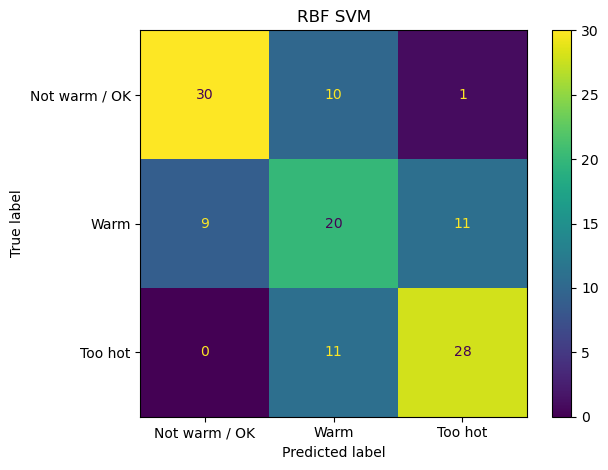

In [7]:
X_train = train_df[FEATURES].copy()
y_train = train_df["thermal_class_code"].astype(int).copy()

X_test = test_df[FEATURES].copy()
y_test = test_df["thermal_class_code"].astype(int).copy()

print("Features:")
print(FEATURES)

print("\nX_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

fitted_models, cv_results = train_candidate_models(
    X_train,
    y_train,
)

print("\nTraining CV results:")
display(cv_results)

selected_model_name = cv_results.iloc[0]["model"]

print(
    "\nModel selected using training CV only:",
    selected_model_name,
)

test_metrics, test_outputs = evaluate_candidate_models(
    fitted_models,
    X_test,
    y_test,
)

print("\nHeld-out test metrics:")
display(test_metrics)

print_detailed_evaluation(
    selected_model_name,
    y_test,
    test_outputs[selected_model_name]["pred"],
)

In [8]:
# Per-city confirmation for the model selected by TRAINING CV.
selected_pred = test_outputs[selected_model_name]["pred"]
selected_prob = test_outputs[selected_model_name]["prob"]

test_eval = test_df.copy()
test_eval["prediction"] = selected_pred

city_rows = []

for city in sorted(test_eval["city"].dropna().unique()):
    mask = test_eval["city"].eq(city).to_numpy()

    city_rows.append(
        metric_row(
            city,
            y_test.to_numpy()[mask],
            selected_pred[mask],
            selected_prob[mask],
        )
    )

city_metrics = pd.DataFrame(city_rows)

print("Selected-model performance by city:")
display(city_metrics)

Selected-model performance by city:


,model,macro_f1,balanced_accuracy,ordinal_mae,brier
0,Madrid,0.510591,0.516667,0.421053,0.437864
1,Warsaw,0.630045,0.615479,0.301587,0.420866


In [9]:
cv_output = RESULTS_DIR / "experiment_6_weather_personal_threshold_cv_results.csv"
test_output = RESULTS_DIR / "experiment_6_weather_personal_threshold_test_metrics.csv"
city_output = RESULTS_DIR / "experiment_6_weather_personal_threshold_city_metrics.csv"

cv_results.to_csv(cv_output, index=False)
test_metrics.to_csv(test_output, index=False)
city_metrics.to_csv(city_output, index=False)

experiment_artifact_dir = ARTIFACTS_DIR / "experiment_6_weather_personal_threshold"
experiment_artifact_dir.mkdir(parents=True, exist_ok=True)

kind, selected_model = fitted_models[selected_model_name]

bundle = {
    "experiment": "experiment_6_weather_personal_threshold",
    "selected_by": "training_cv_macro_f1",
    "selected_model_name": selected_model_name,
    "model_kind": kind,
    "features": FEATURES,
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "class_names": CLASS_NAMES,
    "model": selected_model,
}

artifact_path = (
    experiment_artifact_dir
    / "selected_model.joblib"
)

joblib.dump(bundle, artifact_path)

print("Saved CV results:", cv_output)
print("Saved test results:", test_output)
print("Saved city results:", city_output)
print("Saved selected model bundle:", artifact_path)

Saved CV results: ai/thermal_model\results\experiment_6_weather_personal_threshold_cv_results.csv
Saved test results: ai/thermal_model\results\experiment_6_weather_personal_threshold_test_metrics.csv
Saved city results: ai/thermal_model\results\experiment_6_weather_personal_threshold_city_metrics.csv
Saved selected model bundle: ai/thermal_model\artifacts\experiment_6_weather_personal_threshold\selected_model.joblib


## Interpretation

Compare Experiment 6 against both:
- Experiment 2: does wind/solar add value beyond the personal threshold?
- Experiment 5: does the personal threshold add value beyond richer weather?

This is the strongest candidate feature set if it improves Macro-F1 consistently and the
personal threshold can realistically be collected by ShadeAdapt.